In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Set device to GPU if available, else CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [2]:
# Image preprocessing, Normalization, and Data augmentation
train_transform = transforms.Compose([
    transforms.RandomRotation(10), # Data augmentation
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) # Normalization
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Downloading the EMNIST Balanced dataset
train_data = datasets.EMNIST(
    root="./data",
    split="balanced",
    train=True,
    download=True,
    transform=train_transform
)

test_data = datasets.EMNIST(
    root="./data",
    split="balanced",
    train=False,
    download=True,
    transform=test_transform
)

# Creating DataLoaders for batching
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

print(f"Training samples: {len(train_data)}")
print(f"Testing samples: {len(test_data)}")

Training samples: 112800
Testing samples: 18800


In [3]:
class HandwrittenCharacterCNN(nn.Module):
    def __init__(self):
        super(HandwrittenCharacterCNN, self).__init__()
        
        # Convolutional Block 1
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Convolutional Block 2
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        
        # Flatten layer
        self.flatten = nn.Flatten()
        
        # Fully connected layers (EMNIST balanced has 47 classes)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 47) 

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x) 
        return x

model = HandwrittenCharacterCNN().to(device)
print(model)

HandwrittenCharacterCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=47, bias=True)
)


In [4]:
# Cross-entropy loss and Adam optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5
print("🔥 Starting training...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Zero the gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backpropagation and optimization
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        
    print(f"Epoch {epoch+1}/{epochs} - Loss: {running_loss/len(train_loader):.4f}")
    
print("✅ Training Complete!")

🔥 Starting training...
Epoch 1/5 - Loss: 0.7360
Epoch 2/5 - Loss: 0.4435
Epoch 3/5 - Loss: 0.3924
Epoch 4/5 - Loss: 0.3608
Epoch 5/5 - Loss: 0.3381
✅ Training Complete!


🎯 Validation Accuracy: 86.97%


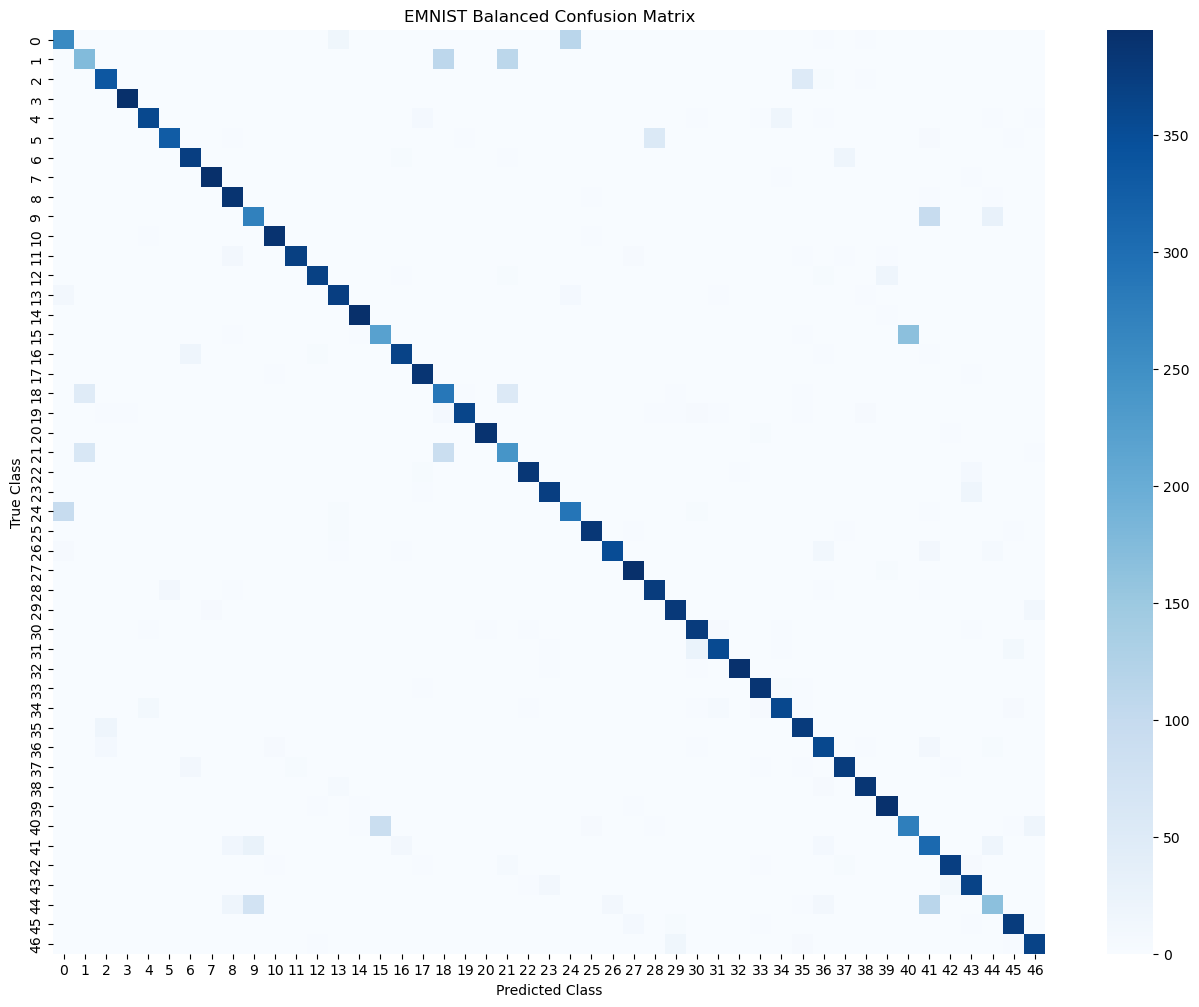

In [5]:
def evaluate_model():
    model.eval()
    all_preds = []
    all_labels = []
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1) 
            
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    print(f"🎯 Validation Accuracy: {100 * correct / total:.2f}%")
    
    # Confusion matrix generation
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(16, 12))
    sns.heatmap(cm, cmap="Blues", annot=False)
    plt.title("EMNIST Balanced Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.show()

# Run the evaluation
evaluate_model()